In [33]:
import pandas as pd
import matplotlib.pyplot as plt

In [34]:
dict_faturamento = {
    'data_ref': [
        '2023-01-01', 
        '2020-02-01', 
        '2021-03-01', 
        '2022-04-01', 
        '2023-05-01',
        '2023-06-01', 
        '2020-07-01', 
        '2021-08-01', 
        '2022-09-01', 
        '2023-10-01',
        '2022-11-01', 
        '2023-12-01',
        ],
    'valor': [
        400000, 
        890000, 
        760000, 
        430000, 
        920000,
        340000, 
        800000, 
        500000, 
        200000, 
        900000,
        570000, 
        995000,
        ]
}

In [35]:
dict_faturamento

{'data_ref': ['2023-01-01',
  '2020-02-01',
  '2021-03-01',
  '2022-04-01',
  '2023-05-01',
  '2023-06-01',
  '2020-07-01',
  '2021-08-01',
  '2022-09-01',
  '2023-10-01',
  '2022-11-01',
  '2023-12-01'],
 'valor': [400000,
  890000,
  760000,
  430000,
  920000,
  340000,
  800000,
  500000,
  200000,
  900000,
  570000,
  995000]}

In [36]:
df_faturamento = pd.DataFrame.from_dict(dict_faturamento)

df_faturamento

,data_ref,valor
0,2023-01-01,400000
1,2020-02-01,890000
2,2021-03-01,760000
3,2022-04-01,430000
4,2023-05-01,920000
5,2023-06-01,340000
6,2020-07-01,800000
7,2021-08-01,500000
8,2022-09-01,200000
9,2023-10-01,900000


In [37]:
print(f'Média das vendas R${df_faturamento.valor.mean():.2f}')

Média das vendas R$642083.33


In [38]:
df_faturamento.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   data_ref  12 non-null     str  
 1   valor     12 non-null     int64
dtypes: int64(1), str(1)
memory usage: 444.0 bytes


In [39]:
df_faturamento['data_ref'] = pd.to_datetime(df_faturamento.data_ref)

<Axes: ylabel='data_ref'>

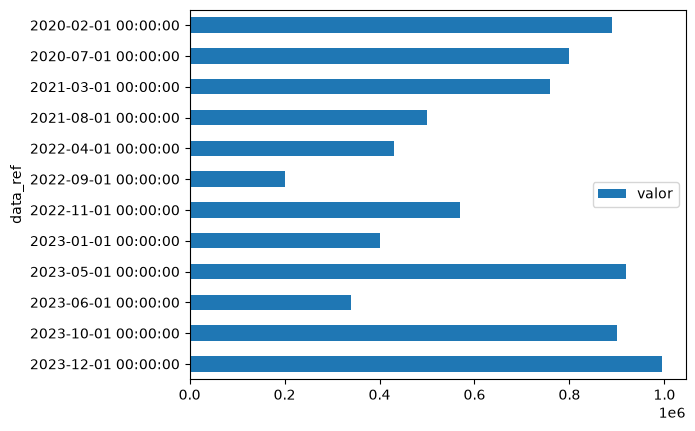

In [40]:
df_faturamento.sort_values(by='data_ref', ascending=False).plot.barh(x='data_ref', y='valor')

In [41]:
df_faturamento['ano'] = df_faturamento['data_ref'].dt.year

In [65]:
df_faturamento['num_mes'] = df_faturamento['data_ref'].dt.month

In [66]:
df_mes = df_faturamento.groupby('num_mes')['valor'].sum().reset_index()

In [64]:
mapa_meses = {
    1: 'Jan', 2: 'Fev', 3: 'Mar', 4: 'Abr', 5: 'Mai', 6: 'Jun',
    7: 'Jul', 8: 'Ago', 9: 'Set', 10: 'Out', 11: 'Nov', 12: 'Dez'
}

In [67]:
df_mes['mes'] = df_mes['num_mes'].map(mapa_meses)

In [69]:
df_novo = df_faturamento.groupby('ano')['valor'].sum().reset_index()

df_novo

,ano,valor
0,2020,1690000
1,2021,1260000
2,2022,1200000
3,2023,3555000


In [45]:
df_mes

,mes,valor
0,1,400000
1,2,890000
2,3,760000
3,4,430000
4,5,920000
5,6,340000
6,7,800000
7,8,500000
8,9,200000
9,10,900000


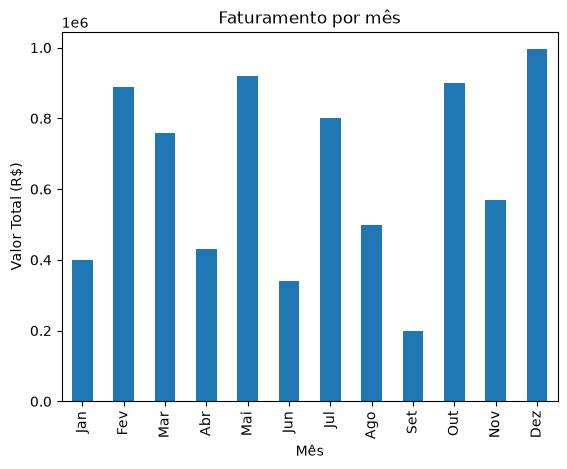

In [70]:
df_mes.plot.bar(x='mes', y='valor', legend=False)
plt.title('Faturamento por mês')
plt.xlabel('Mês')
plt.ylabel('Valor Total (R$)')
plt.show()

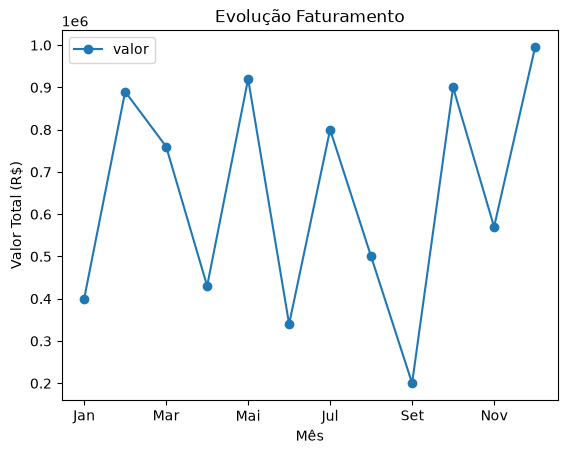

In [71]:
df_mes.plot.line(x='mes', y='valor', marker='o')
plt.title('Evolução Faturamento')
plt.xlabel('Mês')
plt.ylabel('Valor Total (R$)')
plt.show()

<Axes: ylabel='ano'>

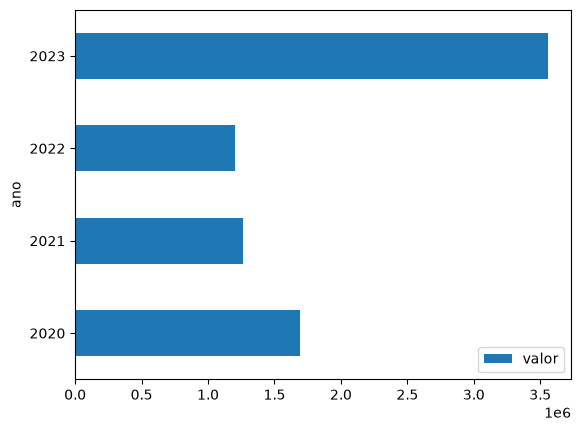

In [48]:
df_novo.sort_values(by='ano').plot.barh(x='ano', y='valor')